# Seminar 3: GANs — based on GANs-2.ipynb

This edition retains the base notebook's convolutional Generator/Discriminator, upsampling
blocks, alternating training, and optional conditional/f-GAN sections. It is **not the separate
MLP lesson**. Portability, numerical, optimizer, and classroom-runtime fixes are documented below.

## One hour, one main experiment

| Time | Focus | What to learn |
|---|---|---|
| 0–7 | What G and D do | Generation is not reconstruction; D is learned, not pretrained |
| 7–15 | MNIST zeros and ranges | Match real/fake pixel ranges; inspect training examples |
| 15–25 | Convolutional networks | Trace noise → image → score, without deriving convolutions |
| 25–40 | Alternating updates | Know targets, detach, backward, and optimizer.step |
| 40–50 | Inspect training/results | Check plausibility and variation, not only losses |
| 50–60 | Questions and recap | Explain the mechanism and its limitations |

**Stop before the appendices.** Conditional CIFAR-100 and f-GAN remain available but are OFF
by default, not extra preparation for this hour. You do not need their derivations today.

**Prerequisites:** Python loops/functions, tensors/batches, neural-network weights, and the
idea of gradient descent. `backward()` computes gradients; `step()` changes weights.
Students do not need to know GANs, Fenchel conjugates, or Wasserstein distance in advance.

**Colab:** upload this single notebook, optionally select a GPU runtime, then run top to bottom.
**Local:** Python 3.10+ Jupyter/VS Code kernel. Setup installs only missing packages. If an
existing torch/torchvision pair is incompatible, use a fresh environment or Colab; we do not
silently replace it. No project folder, Google Drive, or external helper file is required.
MNIST downloads automatically. Initial package/data downloads require internet and are not
included in the training time cap: run setup before class.

Training is capped at 1200 minibatches or approximately 120 seconds, checked between batches.
This is a learning-mechanics demonstration, not a promise of convergence. Teacher saved outputs
are the fallback if a student's runtime fails. Hosted Colab/GPU must not be assumed tested
just because CPU tests pass; see the accompanying verification report.


In [1]:
# Portable setup: no course paths or pretrained checkpoints.
import sys, subprocess, importlib.util, tempfile, time
from pathlib import Path
if sys.version_info < (3, 10):
    raise RuntimeError('Use Python 3.10+ or Colab.')
packages = {'torch':'torch', 'torchvision':'torchvision', 'matplotlib':'matplotlib', 'tqdm':'tqdm'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42)
_can_compile = False
DATA_DIR = Path(tempfile.gettempdir()) / 'dgm_seminar3_mnist'
OUTPUT_DIR = Path(tempfile.mkdtemp(prefix='gans2-results-'))
BASE_CHANNELS = 8  # Original architecture, narrower layers for a short CPU/GPU lesson.
#MAX_STEPS = 1200
#MAX_SECONDS = 120
MAX_STEPS = float("inf")
MAX_SECONDS = float("inf")
RUN_CONDITIONAL = True  # Optional CIFAR-100 appendix; downloads a separate dataset.
RUN_FGAN = True        # Optional JSD f-GAN appendix; not part of the hour.
print('Device:', device, '| torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Data:', DATA_DIR, '| temporary results:', OUTPUT_DIR)


Device: cuda | torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
Data: /tmp/dgm_seminar3_mnist | temporary results: /tmp/gans2-results-vpzaik5a


## Overview

**Generative Adversarial Networks (GANs)** are a class of generative models introduced by Ian Goodfellow and colleagues in 2014. They consist of two neural networks (a Generator and a Discriminator) trained in a min-max (adversarial) game:
- The **Generator** ($G$) aims to produce synthetic data indistinguishable from real data.
- The **Discriminator** ($D$) tries to discriminate between real and fake data.

The training objective can be summarized as:
$$
\min_G \max_D \; \mathcal{L}(G, D) = \mathbb{E}_{x \sim p_\text{data}}[\log D(x)] \;+\; \mathbb{E}_{z \sim p_z}[\log (1 - D(G(z)))]
$$

where $x$ is real data from distribution $p_\text{data}$, and $z$ is noise drawn from a prior $p_z$ (e.g., Gaussian). Over training:
- $D$ learns to give a high confidence to real samples and low confidence to generated samples.
- $G$ learns to fool $D$ by producing realistic samples.

In this seminar, we'll cover:
1. **Unconditional GAN** on MNIST zeros.
2. **Conditional GAN** on CIFAR100.
3. **f-GAN** variants with different divergences.

We'll also introduce important **engineering tips and tricks**, including:
- One-sided label smoothing ([paper](https://arxiv.org/abs/1606.03498))
- Gradient clipping
- Dropout in the Discriminator
- Decaying latent variance for inference
- Balanced update rates
- Batch Normalization in the generator

### Task: generate, not reconstruct

**Idea / focus:** We train on zeros only to keep one short task. G gets random numbers, not a photograph to restore. D learns dataset-versus-generated labels, not the digit classes. The data labels are used only to filter zeros.

**Ask:** Is generating only zeros proof of mode collapse?

**Your answer:** …

## Data Loading & Preprocessing

We download MNIST, select zeros, resize to 32×32, and normalize to [−1,1]. The architectures and training pattern come from your base notebook. Focus on the main loop; smoothing, clipping, dropout, and schedules are implementation choices, not a list of techniques to memorize. We do not change inference noise variance in the core lesson.

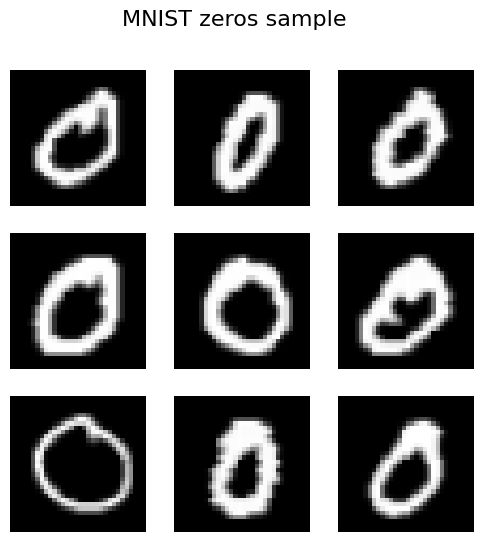

In [2]:
# Data Hyperparameters
batch_size = 32
image_size = 32

transform_mnist = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]) # map to [-1, 1]
])

mnist_dataset = torchvision.datasets.MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform_mnist
)


class OnlyZerosDataset(torch.utils.data.Dataset):
    """
    Dataset of only digit "0" from the MNIST dataset
    """
    def __init__(self, mnist_dataset):
        indices = (mnist_dataset.targets == 0).nonzero(as_tuple=True)[0]
        self.images = [mnist_dataset[int(j)][0] for j in indices]
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        return self.images[idx]

zeros_dataset = OnlyZerosDataset(mnist_dataset)
zeros_loader = DataLoader(zeros_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

# A helper function for un-normalizing the image so we can visualize it properly
def process_image(img_tensor):
    """
    Un-normalize a grayscale image from [-1, 1] -> [0, 1] and move it to CPU for plotting.
    """
    img_tensor = img_tensor.squeeze(0).detach().cpu()
    img_tensor = (img_tensor + 1) / 2
    return img_tensor

# Quick sample visualization
plt.figure(figsize=(6, 6))
for i in range(1, 10):
    img = zeros_dataset[i]
    plt.subplot(3, 3, i)
    plt.imshow(process_image(img), cmap="gray")
    plt.axis("off")
plt.suptitle("MNIST zeros sample", fontsize=16)
plt.show()
assert len(zeros_dataset) > batch_size
assert zeros_dataset[0].shape == (1, 32, 32)

### Focus on shapes

**Idea / focus:** G starts with noise of shape (batch,4,4,4). Three upsampling blocks produce 8×8, 16×16, then 32×32 images. D reduces the image to one raw score. Tanh matches our [−1,1] real-image range. BatchNorm tracks batch statistics; eval() matters for sampling. No network is pretrained.

**Ask:** Why is there no sigmoid at the end of D?

**Your answer:** …

## Unconditional GAN

In an **unconditional GAN**, we do not provide any class labels or auxiliary information. The Generator simply maps random noise to images, and the Discriminator tries to distinguish those images from real data.  

**Key steps**:
1. Sample noise $z \sim \mathcal{N}(0,I)$.  
2. Generate a fake image $G(z)$.  
3. The Discriminator sees both real and fake images, outputs real/fake scores.  
4. Update $D$ to better separate real vs. fake.  
5. Update $G$ to produce more convincing images that fool $D$.

In [3]:
class UpsampleBlock(nn.Module):
    """
    Increases the spatial resolution by factor 2 using bilinear upsampling,
    then a Conv -> BN -> LeakyReLU block repeated.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True),
        )
    def forward(self, x):
        return self.layers(x)


class DownsampleBlock(nn.Module):
    """
    Decreases the spatial resolution by factor 2 with stride=2 convolution.
    """
    def __init__(self, in_channels, out_channels, dropout_p=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(dropout_p),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(dropout_p),
        )
    def forward(self, x):
        return self.layers(x)


class Generator(nn.Module):
    """
    Unconditional Generator for MNIST zeros:
    - We create random noise of shape (noise_channels, noise_spatial_size, noise_spatial_size).
    - 3 UpsampleBlocks to get from 4x4 to 32x32.
    - Final conv1x1 -> Tanh to produce output image in [-1,1].
    - We'll allow a 'noise_factor' for inference so we can reduce noise variance.
    """
    def __init__(self, noise_channels=4, noise_spatial_size=4, image_channels=1, base_channels=32):
        super().__init__()
        self.noise_channels = noise_channels
        self.noise_spatial_size = noise_spatial_size
        # We'll go from base_channels up to 4*base_channels in steps
        # so that each UpsampleBlock doubles the number of channels.
        # This is adjustable to get deeper G if needed.
        self.layers = nn.Sequential(
            UpsampleBlock(noise_channels, base_channels),            # 4x4 -> 8x8
            UpsampleBlock(base_channels, base_channels*2),           # 8x8 -> 16x16
            UpsampleBlock(base_channels*2, base_channels*4),         # 16x16 -> 32x32
            nn.Conv2d(base_channels*4, image_channels, kernel_size=1),
            nn.Tanh()
        )

    def forward(self, batch_size, device, noise_factor=1.0):
        # Create random latent: shape (batch_size, noise_channels, noise_spatial_size, noise_spatial_size)
        latent = torch.randn(
                    batch_size,
                    self.noise_channels,
                    self.noise_spatial_size,
                    self.noise_spatial_size,
                    device=device
                )
        latent = latent * noise_factor  # Decay latent variance on inference if needed
        return self.layers(latent)


class Discriminator(nn.Module):
    """
    Unconditional Discriminator for MNIST zeros:
    - 3 DownsampleBlocks (from 32x32 to 4x4).
    - A final "fully-convolutional" approach:
        * Instead of an fc layer, do a convolution that yields 1 channel of size 4x4,
          and then a global average to produce a single scalar for the real/fake score.
    - We also incorporate dropout in the DownsampleBlocks for better regularization.
    """
    def __init__(self, image_channels=1, base_channels=32, dropout_p=0.3):
        super().__init__()
        self.main = nn.Sequential(
            DownsampleBlock(image_channels, base_channels, dropout_p=dropout_p),       # 32x32 -> 16x16
            DownsampleBlock(base_channels, base_channels*2, dropout_p=dropout_p),      # 16x16 -> 8x8
            DownsampleBlock(base_channels*2, base_channels*4, dropout_p=dropout_p)     # 8x8 -> 4x4
        )

        self.conv_out = nn.Conv2d(base_channels*4, 1, kernel_size=4, stride=1)

    def forward(self, x):
        x = self.main(x)      # shape is (N, 128, 4, 4) if base_channels=32*4=128
        x = self.conv_out(x)  # shape (N, 1, 1, 1)
        return x.view(-1, 1)  # Flatten to (N, 1)

In [4]:
# Training Hyperparameters
lrG = 0.0001    # Generator learning rate
lrD = 0.0001    # Discriminator learning rate
num_epochs = 30
grad_clip_value = 1.0
noise_channels = 4
noise_spatial_size = 4  # We'll create noise of shape (4,4)
label_smoothing = 0.9  # one-sided label smoothing
update_ratio = 1  # how many times to update D before G

**Keep update_ratio=1 today:** one D update and one G update per batch. Other ratios are outside this lesson; low losses alone do not tell you which network needs more updates.

In [5]:
# Create G & D
generator = Generator(
    noise_channels=noise_channels,
    noise_spatial_size=noise_spatial_size,
    image_channels=1,
    base_channels=BASE_CHANNELS
)

discriminator = Discriminator(
    image_channels=1,
    base_channels=BASE_CHANNELS,
    dropout_p=0.3
)

# (Optional) compile with PyTorch 2.5 for speed (CUDA/CPU only)
if _can_compile:
    generator = torch.compile(generator)
    discriminator = torch.compile(discriminator)

# Send models to device
generator.to(device)
discriminator.to(device)

# Create optimizers
optim_G = optim.Adam(generator.parameters(), lr=lrG)
optim_D = optim.Adam(discriminator.parameters(), lr=lrD, betas=(0.5, 0.999))

scheduler_G = optim.lr_scheduler.StepLR(optim_G, step_size=20, gamma=0.5)
scheduler_D = optim.lr_scheduler.StepLR(optim_D, step_size=20, gamma=0.5)

losses = {"D": [], "G": []}

fixed_noise = torch.randn(16, noise_channels, noise_spatial_size, noise_spatial_size, device=device)
generator.eval()
with torch.no_grad():
    initial_samples = generator.layers(fixed_noise).cpu()
generator.train()


Generator(
  (layers): Sequential(
    (0): UpsampleBlock(
      (layers): Sequential(
        (0): Upsample(scale_factor=2.0, mode='bilinear')
        (1): Conv2d(4, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (2): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (3): LeakyReLU(negative_slope=0.2, inplace=True)
        (4): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (5): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (6): LeakyReLU(negative_slope=0.2, inplace=True)
      )
    )
    (1): UpsampleBlock(
      (layers): Sequential(
        (0): Upsample(scale_factor=2.0, mode='bilinear')
        (1): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (3): LeakyReLU(negative_slope=0.2, inplace=True)
        (4): Conv2d(16, 16, kernel_size=(3, 3), strid

### The four lines worth understanding

**Idea / focus:** zero_grad clears old gradients; detach blocks G gradients on D’s turn; backward computes gradients; the selected optimizer changes its own model. D learns real≈0.9 (one-sided smoothing), fake=0. G targets 1: it wants D to accept its outputs. G uses a non-saturating loss, not the minimax G loss. This inherited loop computes D gradients during G’s turn, but only steps G; D gradients are cleared next turn.

**Ask:** Why detach fake images for D, but not for G?

**Your answer:** …

Epoch 1/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [1/30] | D Loss: 0.3740 | G Loss: 1.4512


Epoch 2/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [2/30] | D Loss: 0.3360 | G Loss: 2.7232


Epoch 3/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [3/30] | D Loss: 0.2824 | G Loss: 2.9358


Epoch 4/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [4/30] | D Loss: 0.2628 | G Loss: 2.8362


Epoch 5/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [5/30] | D Loss: 0.2961 | G Loss: 3.0544


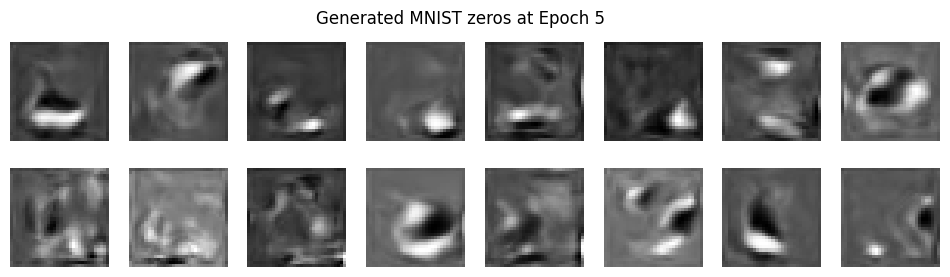

Epoch 6/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [6/30] | D Loss: 0.2371 | G Loss: 3.7360


Epoch 7/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [7/30] | D Loss: 0.2512 | G Loss: 4.7363


Epoch 8/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [8/30] | D Loss: 0.2183 | G Loss: 4.7593


Epoch 9/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [9/30] | D Loss: 0.2073 | G Loss: 4.1729


Epoch 10/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [10/30] | D Loss: 0.2443 | G Loss: 4.8819


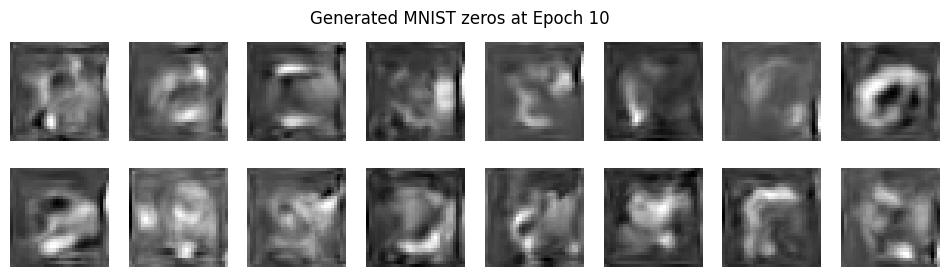

Epoch 11/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [11/30] | D Loss: 0.2052 | G Loss: 4.6166


Epoch 12/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [12/30] | D Loss: 0.2504 | G Loss: 4.8288


Epoch 13/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [13/30] | D Loss: 0.2811 | G Loss: 4.2237


Epoch 14/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [14/30] | D Loss: 0.4826 | G Loss: 3.0801


Epoch 15/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [15/30] | D Loss: 0.2359 | G Loss: 4.1678


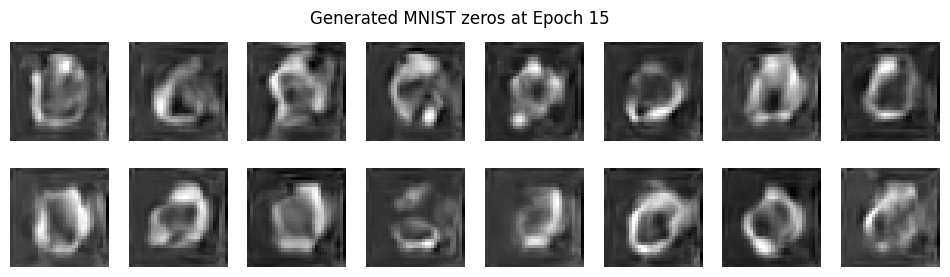

Epoch 16/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [16/30] | D Loss: 0.3334 | G Loss: 3.8916


Epoch 17/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [17/30] | D Loss: 0.4228 | G Loss: 2.1953


Epoch 18/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [18/30] | D Loss: 0.4211 | G Loss: 2.2363


Epoch 19/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [19/30] | D Loss: 0.4802 | G Loss: 2.6624


Epoch 20/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [20/30] | D Loss: 0.5358 | G Loss: 1.9932


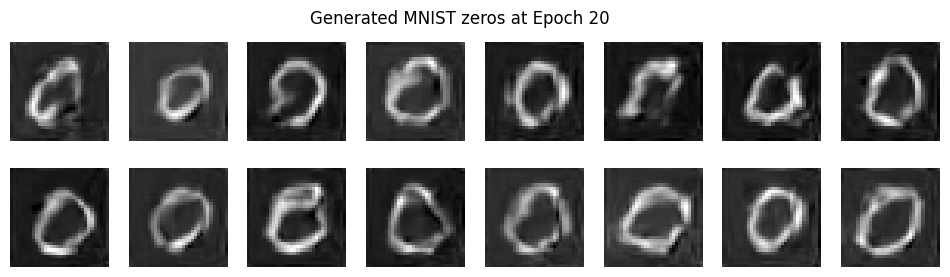

Epoch 21/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [21/30] | D Loss: 0.7296 | G Loss: 1.9231


Epoch 22/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [22/30] | D Loss: 0.5790 | G Loss: 2.3338


Epoch 23/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [23/30] | D Loss: 0.6814 | G Loss: 2.4175


Epoch 24/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [24/30] | D Loss: 0.5526 | G Loss: 1.4964


Epoch 25/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [25/30] | D Loss: 0.6606 | G Loss: 1.9871


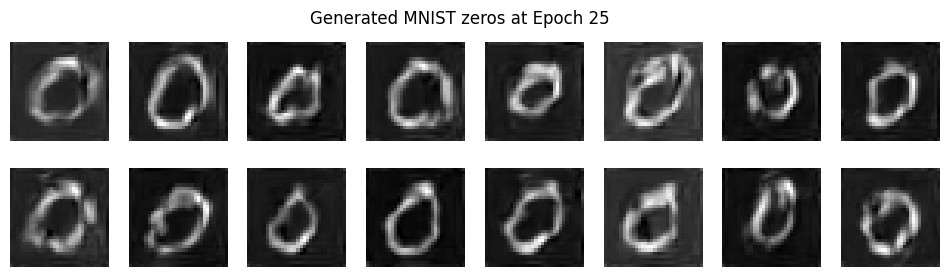

Epoch 26/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [26/30] | D Loss: 0.5144 | G Loss: 1.1621


Epoch 27/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [27/30] | D Loss: 0.6224 | G Loss: 1.4067


Epoch 28/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [28/30] | D Loss: 0.6105 | G Loss: 0.8722


Epoch 29/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [29/30] | D Loss: 0.4716 | G Loss: 1.7608


Epoch 30/30:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [30/30] | D Loss: 0.6156 | G Loss: 1.8316


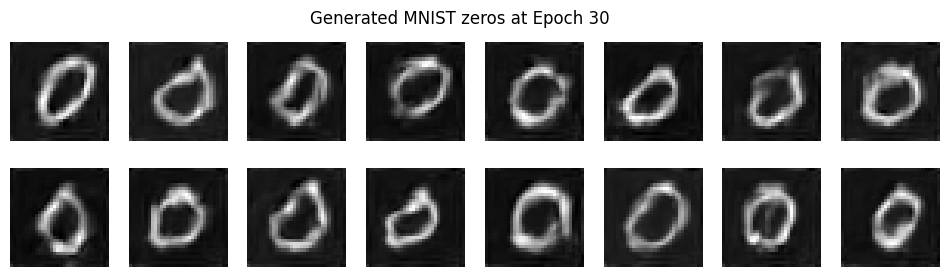

Completed minibatches: 5550


In [6]:
training_started = time.perf_counter()
completed_steps = 0
# Training loop
for epoch in range(num_epochs):
    if completed_steps >= MAX_STEPS or time.perf_counter() - training_started >= MAX_SECONDS:
        break
    for real_images in tqdm(zeros_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False):
        if completed_steps >= MAX_STEPS or time.perf_counter() - training_started >= MAX_SECONDS:
            break
        completed_steps += 1
        real_images = real_images.to(device)
        batch_sz = real_images.size(0)

        # Determine integer steps for D and G
        if update_ratio >= 1.0:
            d_steps = int(update_ratio)
            g_steps = 1
        else:
            d_steps = 1
            g_steps = int(1.0 / update_ratio)

        # -----------------------------
        #  Train Discriminator (d_steps times)
        # -----------------------------

        for _ in range(d_steps):
            optim_D.zero_grad(set_to_none=True)

            # Real images
            real_output = discriminator(real_images)
            real_labels = torch.ones_like(real_output, device=device) * label_smoothing
            loss_real = F.binary_cross_entropy_with_logits(real_output, real_labels)

            # Fake images
            fake_images = generator(batch_sz, device, noise_factor=1.0).detach()
            fake_output = discriminator(fake_images)
            fake_labels = torch.zeros_like(fake_output, device=device)

            loss_fake = F.binary_cross_entropy_with_logits(fake_output, fake_labels)
            loss_D = (loss_real + loss_fake) * 0.5
            loss_D.backward()

            # Gradient clipping
            nn.utils.clip_grad_norm_(discriminator.parameters(), grad_clip_value)
            optim_D.step()

        # -----------------------------
        #  Train Generator (g_steps times)
        # -----------------------------
        for _ in range(g_steps):
            optim_G.zero_grad(set_to_none=True)

            gen_images = generator(batch_sz, device, noise_factor=1.0)
            gen_output = discriminator(gen_images)
            # G wants real=1; only real D targets are smoothed.
            desired_labels = torch.ones_like(gen_output)

            loss_G = F.binary_cross_entropy_with_logits(gen_output, desired_labels)
            loss_G.backward()

            # Gradient clipping
            nn.utils.clip_grad_norm_(generator.parameters(), grad_clip_value)
            optim_G.step()

        # Save final losses from last step
        losses["D"].append(loss_D.item())
        losses["G"].append(loss_G.item())

    # Step the LR schedulers after each epoch
    scheduler_G.step()
    scheduler_D.step()

    print(f"Epoch [{epoch+1}/{num_epochs}] | D Loss: {loss_D.item():.4f} | G Loss: {loss_G.item():.4f}")

    # Save checkpoint every 5 epochs
    if (epoch + 1) % 5 == 0:
        torch.save({
            "epoch": epoch+1,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "optimizer_G_state_dict": optim_G.state_dict(),
            "optimizer_D_state_dict": optim_D.state_dict()
        }, f"{OUTPUT_DIR}/gan_checkpoint_epoch_{epoch+1}.pth")

        # -----------------------------
        # Print some generated zeros every 5 epochs
        # -----------------------------
        generator.eval()
        with torch.no_grad():
            sample_fakes = generator(16, device, noise_factor=1.0).cpu()

        fig, axs = plt.subplots(2, 8, figsize=(12, 3))
        for i in range(16):
            ax = axs[i // 8, i % 8]
            ax.imshow(process_image(sample_fakes[i]), cmap='gray')
            ax.axis("off")
        plt.suptitle(f"Generated MNIST zeros at Epoch {epoch+1}")
        plt.show()
        generator.train()
print("Completed minibatches:", completed_steps)

### Read results honestly

**Idea / focus:** Both opponents change, so GAN losses need not fall smoothly. D loss is a real/fake training score, not a perceptual metric like LPIPS. Inspect images for plausible strokes AND variation. The same fixed noise makes before/after comparison interpretable.

**Ask:** Does D being uncertain prove G is good?

**Your answer:** …

**Short-run caveat:** the checked CPU run produced distorted, low-quality images rather than a converged zero generator. Use this to discuss failure, not as evidence of successful distribution learning. More training or tuning may help but is not guaranteed; neither is required during this hour.

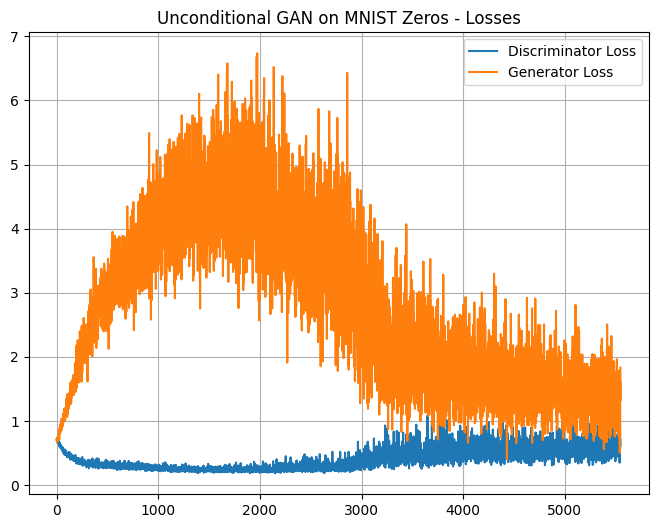

In [7]:
# Plot loss curves
plt.figure(figsize=(8, 6))
plt.plot(losses["D"], label="Discriminator Loss")
plt.plot(losses["G"], label="Generator Loss")
plt.legend()
plt.title("Unconditional GAN on MNIST Zeros - Losses")
plt.grid()
plt.show()

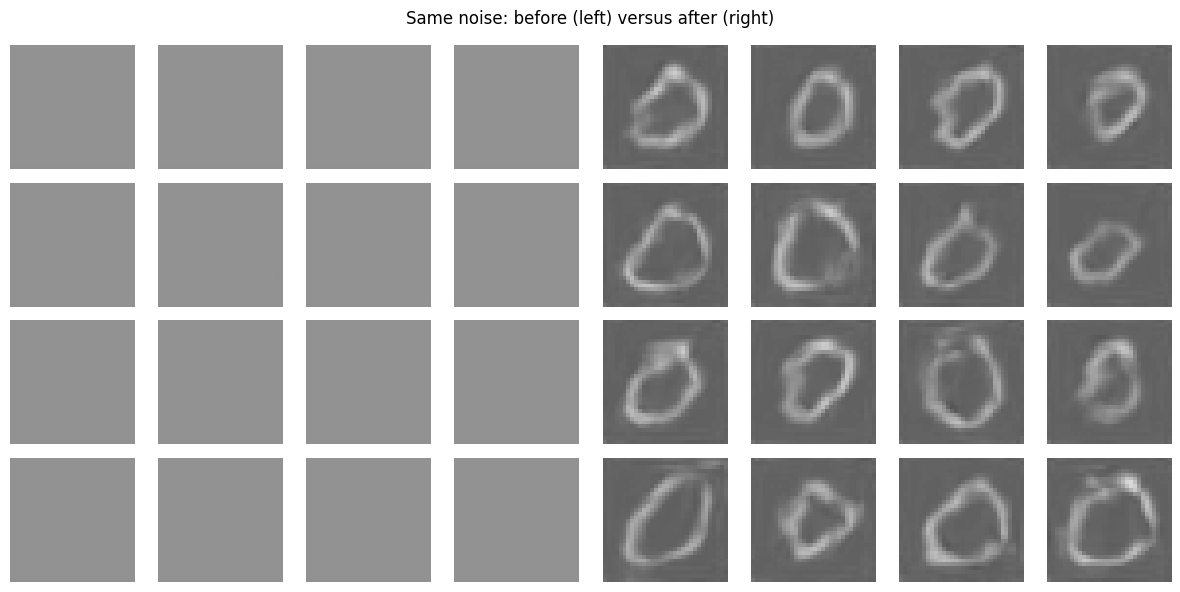

In [8]:
# Fixed input comparison: use exactly the same latent tensors before and after.
generator.eval()
with torch.no_grad():
    final_fakes = generator.layers(fixed_noise).cpu()
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for j in range(16):
    for col_offset, samples in [(0, initial_samples), (4, final_fakes)]:
        ax = axes[j // 4, j % 4 + col_offset]
        ax.imshow(process_image(samples[j]), cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
fig.suptitle('Same noise: before (left) versus after (right)')
plt.tight_layout(); plt.show()
assert torch.isfinite(final_fakes).all()
assert final_fakes.shape == (16, 1, 32, 32)


## Recap and exit ticket · finish by minute 60

1. What enters G, and what leaves it?
2. Why do real and fake images need the same numerical range?
3. Why does G target real=1 while D targets fake=0?
4. Do we need D when generating after training?
5. Are almost-identical good-looking zeros sufficient?

**Takeaway:** G learns to generate a distribution through D's feedback. Inspect fidelity and
variation separately; no GAN loss is a complete quality score. Copying cannot be ruled out
by this grid. A stronger evaluation uses held-out data and training-neighbor inspection.

**STOP THE LIVE LESSON HERE.** The appendices below are not part of the 60-minute plan.


## Optional appendix A: Conditional GAN — OFF by default

Set RUN_CONDITIONAL=True in setup only if deliberately doing a separate extension. This retains the base CIFAR-100 experiment and downloads CIFAR-100; short training will not converge. Not required today.

A **Conditional GAN (cGAN)** incorporates **class labels** or some auxiliary information into both $G$ and $D$.  

- The **Generator** receives both noise $z$ and a label $y$ as input.  
- The **Discriminator** sees both the real/fake image and the corresponding label $y$.  

This allows the GAN to learn class-specific image generation, improving control over the outputs.

In [9]:
if RUN_CONDITIONAL:
    # We'll build a config dict to keep track of parameters easily.

    class DotDict(dict):
        """Helper class to allow dot notation: d.key -> d['key']"""
        __getattr__ = dict.__getitem__
        __setattr__ = dict.__setitem__

    config = DotDict({
        "noise_channels": 4,
        "noise_spatial_size": 4,
        "image_size": 32,
        "image_channels": 3,
        "batch_size": 32,
        "num_attrs": 100,  # CIFAR100 has 100 classes
        "device": device,
        "max_epochs": 30,
        "grad_clip_value": 1.0,
        "lrG": 0.0002,
        "lrD": 0.0002,
        "label_smoothing": 0.9
    })
else:
    print("Conditional appendix skipped.")

In [10]:
if RUN_CONDITIONAL:
    # Prepare CIFAR100
    transform_cifar = transforms.Compose([
        transforms.Resize((config.image_size, config.image_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5],[0.5, 0.5, 0.5])
    ])
    cifar_dataset = torchvision.datasets.CIFAR100(
        root=str(DATA_DIR / "cifar100"),
        train=True,
        transform=transform_cifar,
        download=True
    )
    cifar_loader = DataLoader(cifar_dataset, batch_size=config.batch_size, shuffle=True, drop_last=True)
else:
    print("Conditional appendix skipped.")

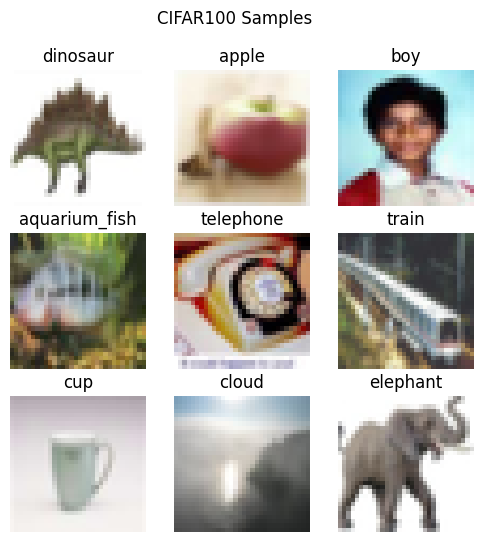

In [11]:
if RUN_CONDITIONAL:
    # Helper function for unnormalizing an image
    def process_cifar_image(img_tensor):
        """
        Un-normalize from [-1, 1] to [0, 1] and permute (3, H, W) -> (H, W, 3) for plotting.
        """
        img_tensor = img_tensor.permute(1, 2, 0).detach().cpu()
        img_tensor = (img_tensor + 1) / 2
        return img_tensor

    # Quick check of data
    label2name_cifar = {val:key for key,val in cifar_dataset.class_to_idx.items()}
    plt.figure(figsize=(6, 6))
    for i in range(1, 10):
        img, lbl = cifar_dataset[i]
        plt.subplot(3, 3, i)
        plt.imshow(process_cifar_image(img))
        plt.title(label2name_cifar[lbl])
        plt.axis("off")
    plt.suptitle("CIFAR100 Samples")
    plt.show()
else:
    print("Conditional appendix skipped.")

In [12]:
if RUN_CONDITIONAL:
    # Conditional Upsample/Downsample blocks

    class CondUpsampleBlock(nn.Module):
        def __init__(self, in_channels, out_channels):
            super().__init__()
            self.layers = nn.Sequential(
                nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.LeakyReLU(0.2, inplace=True),
            )
        def forward(self, x):
            return self.layers(x)


    class CondDownsampleBlock(nn.Module):
        def __init__(self, in_channels, out_channels, dropout_p=0.3):
            super().__init__()
            self.layers = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Dropout2d(dropout_p),
                nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.LeakyReLU(0.2, inplace=True),
                nn.Dropout2d(dropout_p),
            )
        def forward(self, x):
            return self.layers(x)


    class CondGenerator(nn.Module):
        """
        Conditional generator:
        - We'll embed the label to produce an embedding of shape (1, noise_spatial_size, noise_spatial_size)
        - We'll concatenate that embedding with the random noise along the channel dimension
        - Then pass through upsampling blocks until we reach config.image_size x config.image_size
        """
        def __init__(self, config):
            super().__init__()
            self.config = config
            self.label_embedding = nn.Embedding(config.num_attrs,
                                                config.noise_spatial_size * config.noise_spatial_size)

            # We'll keep doubling the channel count. Start from noise_channels+1
            # because we have noise + label embedding in the channel dimension.
            base_channels = BASE_CHANNELS
            self.initial_channels = config.noise_channels + 1

            self.up1 = CondUpsampleBlock(self.initial_channels, base_channels)       # 4x4 -> 8x8
            self.up2 = CondUpsampleBlock(base_channels, base_channels*2)             # 8x8 -> 16x16
            self.up3 = CondUpsampleBlock(base_channels*2, base_channels*4)           # 16x16 -> 32x32

            self.conv_out = nn.Conv2d(base_channels*4, self.config.image_channels, kernel_size=1)
            self.tanh = nn.Tanh()

        def forward(self, batch_size, labels, device, noise_factor=1.0):
            # Create random noise
            noise = torch.randn(batch_size, self.config.noise_channels,
                                self.config.noise_spatial_size, self.config.noise_spatial_size,
                                device=device)
            noise = noise * noise_factor

            # Create label embedding
            # shape => (batch_size, noise_spatial_size * noise_spatial_size)
            embed = self.label_embedding(labels)
            # reshape => (batch_size, 1, noise_spatial_size, noise_spatial_size)
            embed = embed.view(batch_size, 1, self.config.noise_spatial_size, self.config.noise_spatial_size)

            # concat => shape (batch_size, noise_channels+1, noise_spatial_size, noise_spatial_size)
            x = torch.cat([noise, embed], dim=1)

            x = self.up1(x)
            x = self.up2(x)
            x = self.up3(x)

            x = self.conv_out(x)
            x = self.tanh(x)
            return x


    class CondDiscriminator(nn.Module):
        """
        Conditional discriminator:
        - We'll embed the label to produce an extra channel with the same spatial resolution (config.image_size x config.image_size).
        - We'll concatenate input image + embedded label along the channel dimension.
        - Then pass through downsampling blocks until shape is 4x4.
        - Finally do a fully convolutional approach => conv to 1 dimension => global average => single real/fake score.
        """
        def __init__(self, config, dropout_p=0.3):
            super().__init__()
            self.config = config
            self.label_embedding = nn.Embedding(config.num_attrs,
                                                config.image_size * config.image_size)

            base_channels = BASE_CHANNELS
            # input channels = image_channels + 1
            self.down1 = CondDownsampleBlock(config.image_channels+1, base_channels, dropout_p=dropout_p)     # config.image_size -> config.image_size / 2
            self.down2 = CondDownsampleBlock(base_channels, base_channels*2, dropout_p=dropout_p)             # config.image_size / 2 -> config.image_size / 4
            self.down3 = CondDownsampleBlock(base_channels*2, base_channels*4, dropout_p=dropout_p)           # config.image_size / 4 -> config.image_size / 8

            self.conv_out = nn.Conv2d(base_channels*4, 1, kernel_size=4, stride=1)

        def forward(self, x, labels):
            # x: shape (batch, image_channels, config.image_size, config.image_size)
            # labels: shape (batch,)
            embed = self.label_embedding(labels)  # shape (batch, config.image_size * config.image_size)
            embed = embed.view(-1, 1, self.config.image_size, self.config.image_size)  # shape (batch, 1, config.image_size, config.image_size)
            x = torch.cat([x, embed], dim=1)
            x = self.down1(x)
            x = self.down2(x)
            x = self.down3(x)

            x = self.conv_out(x)  # shape (batch, 1, 1, 1)
            return x.view(-1,1)


    class ConditionalGAN:
        """
        Wraps up the conditional generator & discriminator,
        handles training steps, etc.
        """
        def __init__(self, config):
            self.config = config
            self.G = CondGenerator(config).to(config.device)
            self.D = CondDiscriminator(config, dropout_p=0.3).to(config.device)
            if _can_compile:
                self.G = torch.compile(self.G)
                self.D = torch.compile(self.D)

            self.optim_G = optim.Adam(self.G.parameters(), lr=config.lrG, betas=(0.5, 0.999))
            self.optim_D = optim.Adam(self.D.parameters(), lr=config.lrD, betas=(0.5, 0.999))

        def train_discriminator(self, real_images, labels):
            self.optim_D.zero_grad(set_to_none=True)

            # Real forward
            real_out = self.D(real_images, labels)
            real_labels = torch.ones_like(real_out) * self.config.label_smoothing
            loss_real = F.binary_cross_entropy_with_logits(real_out, real_labels)

            # Fake forward
            fake = self.G(real_images.size(0), labels, self.config.device, noise_factor=1.0).detach()
            fake_out = self.D(fake, labels)
            fake_labels = torch.zeros_like(fake_out)
            loss_fake = F.binary_cross_entropy_with_logits(fake_out, fake_labels)

            loss_D = 0.5 * (loss_real + loss_fake)
            loss_D.backward()
            nn.utils.clip_grad_norm_(self.D.parameters(), self.config.grad_clip_value)
            self.optim_D.step()
            return loss_D.item()

        def train_generator(self, batch_size, labels):
            self.optim_G.zero_grad(set_to_none=True)

            fake = self.G(batch_size, labels, self.config.device, noise_factor=1.0)
            out = self.D(fake, labels)
            target = torch.ones_like(out)
            loss_G = F.binary_cross_entropy_with_logits(out, target)

            loss_G.backward()
            nn.utils.clip_grad_norm_(self.G.parameters(), self.config.grad_clip_value)
            self.optim_G.step()
            return loss_G.item()

        @torch.no_grad()
        def sample(self, n_samples, labels=None, noise_factor=0.7):
            """
            Sample images from the generator, optionally with given labels.
            If labels is None, use random labels in [0, num_attrs).
            """
            if labels is None:
                labels = torch.randint(0, self.config.num_attrs, (n_samples,), device=self.config.device)
            fake = self.G(n_samples, labels, self.config.device, noise_factor=noise_factor)
            return fake.cpu()
else:
    print("Conditional appendix skipped.")


--- Training Conditional GAN on CIFAR100 ---



Epoch 1/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [1/30] | D Loss: 0.7069 | G Loss: 0.8633


Epoch 2/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [2/30] | D Loss: 0.6939 | G Loss: 0.8700


...

Epoch [3/30] | D Loss: 0.6567 | G Loss: 0.8959


Epoch 4/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [4/30] | D Loss: 0.7053 | G Loss: 0.8337


Epoch 5/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [5/30] | D Loss: 0.6624 | G Loss: 0.7679


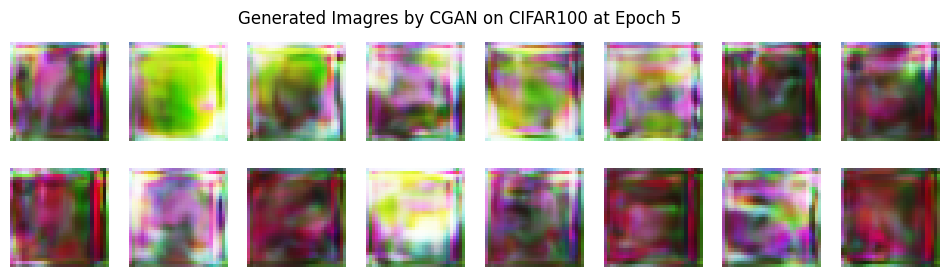

Epoch 6/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [6/30] | D Loss: 0.6205 | G Loss: 0.8298


Epoch 7/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [7/30] | D Loss: 0.5211 | G Loss: 1.5245


Epoch 8/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [8/30] | D Loss: 0.8053 | G Loss: 2.7604


Epoch 9/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [9/30] | D Loss: 0.8862 | G Loss: 0.7945


Epoch 10/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [10/30] | D Loss: 0.6484 | G Loss: 1.0662


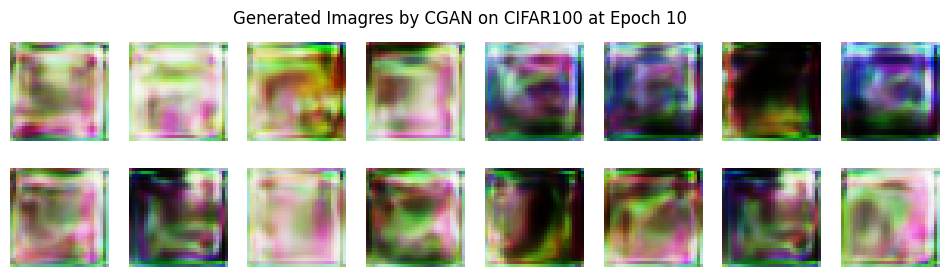

Epoch 11/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [11/30] | D Loss: 0.9156 | G Loss: 1.1833


Epoch 12/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [12/30] | D Loss: 0.3996 | G Loss: 2.0516


Epoch 13/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [13/30] | D Loss: 0.4010 | G Loss: 1.4785


Epoch 14/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [14/30] | D Loss: 0.2903 | G Loss: 1.2855


Epoch 15/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [15/30] | D Loss: 0.5605 | G Loss: 1.2773


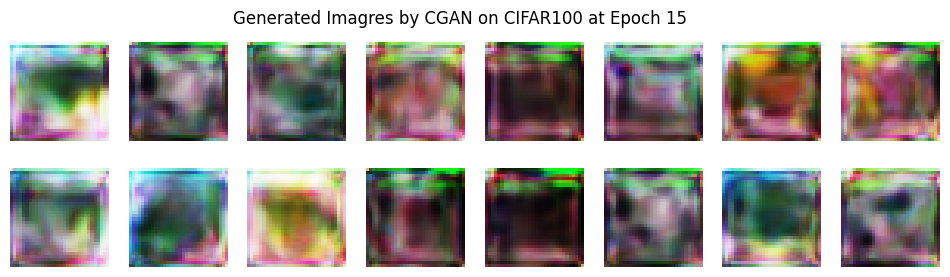

Epoch 16/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [16/30] | D Loss: 0.3106 | G Loss: 1.5536


Epoch 17/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [17/30] | D Loss: 0.3299 | G Loss: 2.7409


Epoch 18/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [18/30] | D Loss: 0.5979 | G Loss: 1.1585


Epoch 19/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [19/30] | D Loss: 0.5297 | G Loss: 3.8408


Epoch 20/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [20/30] | D Loss: 0.2040 | G Loss: 0.6302


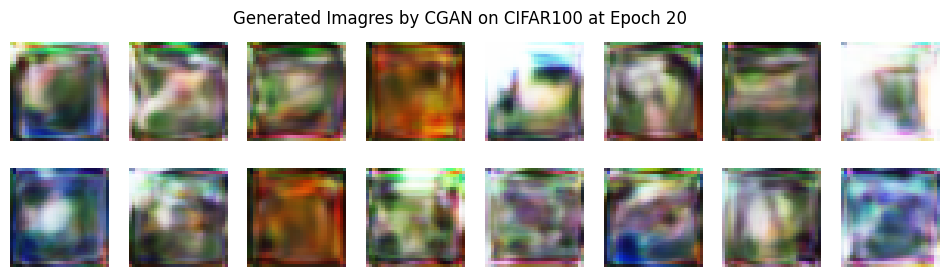

Epoch 21/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [21/30] | D Loss: 0.3144 | G Loss: 5.2866


Epoch 22/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [22/30] | D Loss: 0.3020 | G Loss: 2.9245


Epoch 23/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [23/30] | D Loss: 0.3088 | G Loss: 0.3615


Epoch 24/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [24/30] | D Loss: 0.7036 | G Loss: 1.0327


Epoch 25/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [25/30] | D Loss: 0.3234 | G Loss: 1.1624


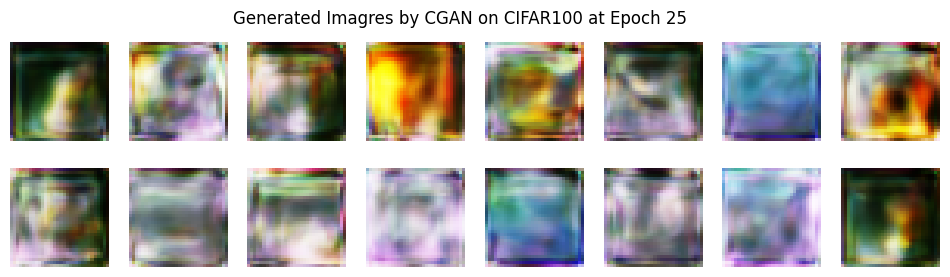

Epoch 26/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [26/30] | D Loss: 0.1895 | G Loss: 4.6642


Epoch 27/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [27/30] | D Loss: 0.2576 | G Loss: 2.5846


Epoch 28/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [28/30] | D Loss: 0.2581 | G Loss: 0.4112


Epoch 29/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [29/30] | D Loss: 0.2349 | G Loss: 2.9926


Epoch 30/30:   0%|          | 0/1562 [00:00<?, ?it/s]

Epoch [30/30] | D Loss: 0.2528 | G Loss: 3.0474


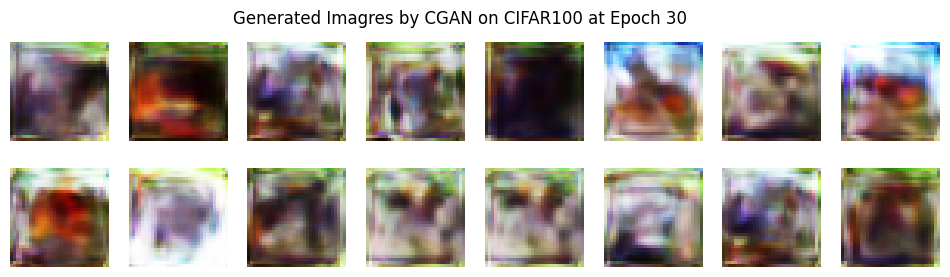

Completed minibatches: 46860


In [13]:
if RUN_CONDITIONAL:
    training_started = time.perf_counter()
    completed_steps = 0
    # Instantiate and train
    cond_gan = ConditionalGAN(config)
    losses_cond = {"D": [], "G": []}

    print("\n--- Training Conditional GAN on CIFAR100 ---\n")
    for epoch in range(config.max_epochs):
        if completed_steps >= MAX_STEPS or time.perf_counter() - training_started >= MAX_SECONDS:
            break
        for real_images, labels in tqdm(cifar_loader, desc=f"Epoch {epoch+1}/{config.max_epochs}", leave=False):
            if completed_steps >= MAX_STEPS or time.perf_counter() - training_started >= MAX_SECONDS:
                break
            completed_steps += 1
            real_images = real_images.to(config.device)
            labels = labels.to(config.device)

            d_loss = cond_gan.train_discriminator(real_images, labels)
            g_loss = cond_gan.train_generator(real_images.size(0), labels)

            losses_cond["D"].append(d_loss)
            losses_cond["G"].append(g_loss)

        print(f"Epoch [{epoch+1}/{config.max_epochs}] | D Loss: {d_loss:.4f} | G Loss: {g_loss:.4f}")

        # Save checkpoint every 5 epochs
        if (epoch + 1) % 5 == 0:
            torch.save({
                "epoch": epoch+1,
                "generator_state_dict": cond_gan.G.state_dict(),
                "discriminator_state_dict": cond_gan.D.state_dict(),
                "optimizer_G_state_dict": cond_gan.optim_G.state_dict(),
                "optimizer_D_state_dict": cond_gan.optim_D.state_dict()
            }, f"{OUTPUT_DIR}/cgan_checkpoint_epoch_{epoch+1}.pth")

            # -----------------------------
            # Print some generated zeros every 5 epochs
            # -----------------------------
            with torch.no_grad():
                sample_labels = torch.randint(0, config.num_attrs, (16,), device=config.device)
                samples = cond_gan.sample(16, labels=sample_labels, noise_factor=1.0)

            fig, axs = plt.subplots(2, 8, figsize=(12, 3))
            for i in range(16):
                ax = axs[i // 8, i % 8]
                ax.imshow(process_cifar_image(samples[i]), cmap='gray')
                ax.axis("off")
            plt.suptitle(f"Generated Imagres by CGAN on CIFAR100 at Epoch {epoch+1}")
            plt.show()
    print("Completed minibatches:", completed_steps)
else:
    print("Conditional appendix skipped.")

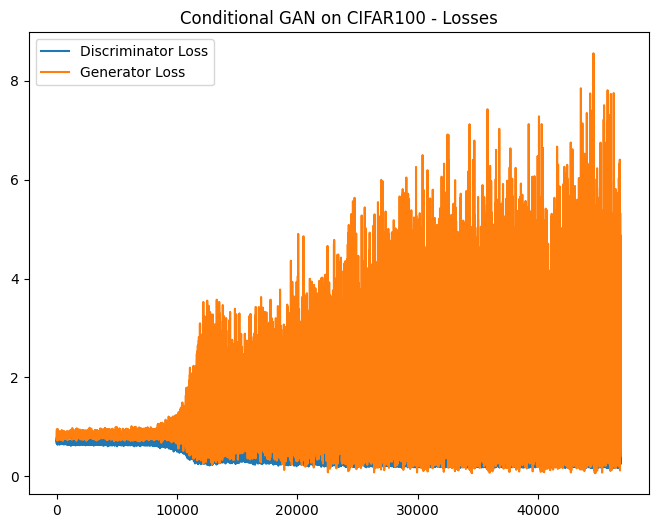

In [14]:
if RUN_CONDITIONAL:
    # Visualize losses
    plt.figure(figsize=(8, 6))
    plt.plot(losses_cond["D"], label="Discriminator Loss")
    plt.plot(losses_cond["G"], label="Generator Loss")
    plt.title("Conditional GAN on CIFAR100 - Losses")
    plt.legend()
    plt.show()
else:
    print("Conditional appendix skipped.")

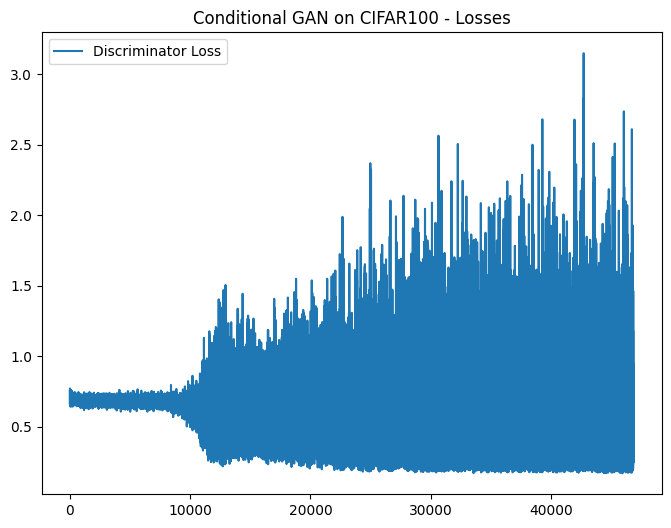

In [29]:
if RUN_CONDITIONAL:
    # Visualize losses
    plt.figure(figsize=(8, 6))
    plt.plot(losses_cond["D"], label="Discriminator Loss")
    #plt.plot(losses_cond["G"], label="Generator Loss")
    plt.title("Conditional GAN on CIFAR100 - Losses")
    plt.legend()
    plt.show()
else:
    print("Conditional appendix skipped.")

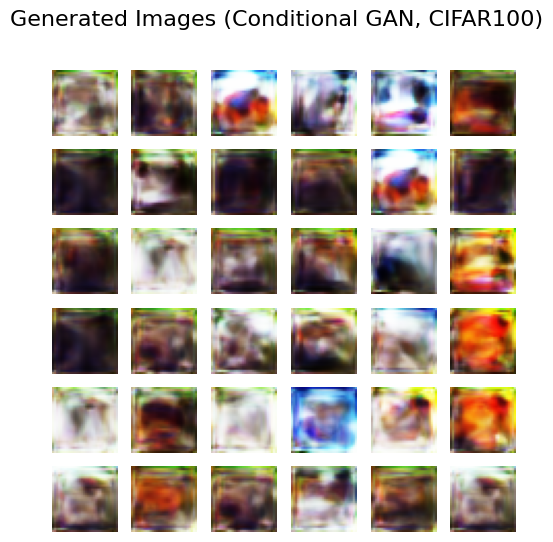

In [15]:
if RUN_CONDITIONAL:
    # Sample and visualize
    cond_gan.G.eval()
    with torch.no_grad():
        # Generate 36 random labels and images
        sample_labels = torch.randint(0, config.num_attrs, (36,), device=config.device)
        samples = cond_gan.sample(36, labels=sample_labels, noise_factor=0.7)

    plt.figure(figsize=(6, 6))
    for i in range(36):
        plt.subplot(6, 6, i+1)
        plt.imshow(process_cifar_image(samples[i]))
        plt.axis("off")
    plt.suptitle("Generated Images (Conditional GAN, CIFAR100)", fontsize=16)
    plt.show()
else:
    print("Conditional appendix skipped.")

In [20]:
class_id = cifar_dataset.class_to_idx["apple"]

sample_labels = torch.full(
    (36,),
    class_id,
    dtype=torch.long,
    device=config.device
)

cond_gan.G.eval()
with torch.no_grad():
    samples = cond_gan.sample(
        36,
        labels=sample_labels,
        noise_factor=1.0
    )

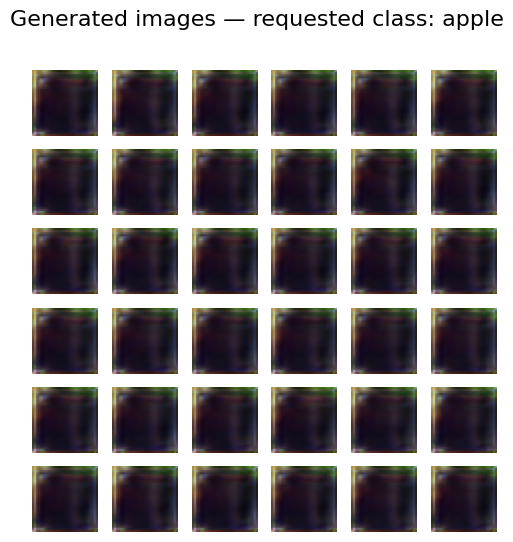

In [28]:
plt.figure(figsize=(6, 6))
for i in range(36):
      plt.subplot(6, 6, i+1)
      plt.imshow(process_cifar_image(samples[i]))
      plt.axis("off")
plt.suptitle("Generated images — requested class: apple", fontsize=16)
plt.show()

### Observations & Advantages of cGAN
- **Label control**: We can direct the generator to produce images of a specific class.  
- **Improved sample variety**: Conditioned on the label, the generator focuses on class-specific features.  
- **Potential for multi-modal generation**: Different classes can lead to diverse generation.

## Optional appendix B: f-GAN — OFF by default

f-GAN changes the variational divergence objective; its critic need not output a probability. Keep RUN_FGAN=False for the live class. The runnable extension is restricted to JSD/GAN, with stable formulas; this is not a claim of validating all listed divergence choices.

**f-GAN** generalizes the GAN training objective by choosing different **f-divergences** (e.g., KLD, JS, Reverse KL, etc.). The objective modifies how $D$ is trained and how the **Generator** updates.  

- $g$ and $f^*$ come from the **Fenchel conjugate**.  
- For certain choices (like "GAN"), we recover the original min-max game.  
- For others (like "JSD", "KLD"), we get different theoretical properties and potentially different training behaviors.

### **Explanation of the Code Implementing f-GAN**

### **1. `Activation_g` Class (Activation Function g(v))**
This class defines the **activation function** $( g(v) $) that depends on the divergence type. This function transforms the discriminator output $( V(x) $) in a way that aligns with the chosen divergence.

#### **Key Divergences and Their Activations**:
- **KLD (Kullback-Leibler Divergence):** $( g(v) = v $) (Identity)
- **Reverse KLD (RKL):** $( g(v) = -\exp(-v) $) (Penalizes low-density regions)
- **Pearson $(\chi^2$) (CHI):** $( g(v) = v $) (Similar to KLD but more sensitive to large deviations)
- **Squared Hellinger (SQH):** $( g(v) = 1 - \exp(-v) $) (Useful for robustness)
- **Jensen-Shannon (JSD):** $( g(v) = \log(2) - \log(1 + e^{-v}) $) (Stable divergence)
- **GAN (Standard GAN Loss):** $( g(v) = -\log(1 + e^{-v}) = \log(\sigma(v)) $) (Log-sigmoid function)

🔹 **Purpose**: The activation function **modifies the discriminator output** before passing it to the loss function.

---

### **2. `Conjugate_f` Class (Fenchel Conjugate $( f^*(t) $))**
This class defines the **Fenchel conjugate** function $( f^*(t) $), which is used in the f-GAN optimization objective. Each divergence has a different conjugate.

#### **Key Divergences and Their Conjugates**:
- **KLD:** $( f^*(t) = \exp(t - 1) $)  
- **Reverse KLD (RKL):** $( f^*(t) = -1 - \log(-t) $)  
- **Pearson \(\chi^2\) (CHI):** $( f^*(t) = 0.25t^2 + t $)  
- **Squared Hellinger (SQH):** $( f^*(t) = t / (1 - t) $)  
- **JSD:** $( f^*(t) = -\log(2 - \exp(t)) $)  
- **GAN:** $( f^*(t) = -\log(1 - \exp(t)) $)  

🔹 **Purpose**: The Fenchel conjugate function **helps approximate the f-divergence** by transforming the discriminator output.

---

### **3. `VLoss` Class (Real Data Loss)**
Defines the expectation **over real data**:
$[
V = \mathbb{E}_{x \sim P} [g(V(x))]
$]
- Uses `Activation_g` to transform \( v \).
- Takes the **mean** over all samples.

🔹 **Purpose**: This term is **maximized** to encourage the discriminator to correctly classify real data.

---

### **4. `QLoss` Class (Fake Data Loss)**
Defines the expectation **over generated (fake) data**:
$[
Q = \mathbb{E}_{x \sim Q} [-f^*(g(V(x)))]
$]
- Uses **both `Activation_g` and `Conjugate_f`** to apply the conjugate transformation.
- Takes the **negative mean**, ensuring proper optimization.

🔹 **Purpose**: This term is **minimized** to encourage the generator to fool the discriminator.

---

## **Simple Algorithm for f-GAN**
**high-level algorithm** implementing f-GAN:

### **1. Initialize**
- Define **generator** \( G(z) \) and **discriminator** \( T(x) \).
- Choose **f-divergence** (GAN, JSD, KLD, etc.).
- Define **activation function** \( g(v) \) and **conjugate function** \( f^*(t) \).

### **2. Training Loop**
For each training step:
1. **Sample real data** $( x \sim P_{\text{data}} )$.
2. **Generate fake data** $( x' = G(z) $), where $( z \sim P_z $).
3. **Compute discriminator loss**:
   - Compute **real data loss**:  
     $[
     V = \mathbb{E}_{x \sim P} [g(V(x))]
     $]
   - Compute **fake data loss**:  
     $[
     Q = \mathbb{E}_{x \sim Q} [-f^*(g(V(x)))]
     $]
   - Optimize **discriminator** to maximize \( V - Q \).
4. **Compute generator loss**:
   - Optimize **generator** to minimize \( Q \), encouraging fake data to match real data.
5. **Update parameters** using backpropagation.

### **3. Repeat Until Convergence**
- The generator improves over time, producing realistic samples.
- The discriminator adapts, but the equilibrium is reached when the generator is indistinguishable from real data.

---

### **Summary**
1. **f-GAN uses f-divergence to measure differences** between real and fake distributions.
2. **Activation functions (`Activation_g`) modify the discriminator's output** based on divergence type.
3. **Fenchel conjugate functions (`Conjugate_f`) reformulate the optimization** to make it computationally feasible.
4. **`VLoss` and `QLoss` define the training objectives** for the discriminator.
5. **Training involves alternating updates to the generator and discriminator** to minimize the divergence.


In [16]:
if RUN_FGAN:
    class Activation_g(nn.Module):
        """
        Activation function g(v) in f-GANs, controlling the divergence type.
        For 'GAN' divergence, it's -log(1+exp(-v)) which is log(sigmoid(v)).
        """
        def __init__(self, divergence="GAN"):
            super().__init__()
            self.divergence = divergence

        def forward(self, v):
            if self.divergence == "KLD":
                return v
            elif self.divergence == "RKL":
                return -torch.exp(-v)
            elif self.divergence == "CHI":
                return v
            elif self.divergence == "SQH":
                return 1 - torch.exp(-v)
            elif self.divergence == "JSD":
                # log(2) - log(1+exp(-v)) = log(2) - softplus(-v)
                return torch.log(torch.tensor(2.0, device=v.device)) - F.softplus(-v)
            elif self.divergence == "GAN":
                # -log(1 + exp(-v)) = log(sigmoid(v))
                return -F.softplus(-v)


    class Conjugate_f(nn.Module):
        """
        Conjugate function f*(t) for different divergences.
        """
        def __init__(self, divergence="GAN"):
            super().__init__()
            self.divergence = divergence

        def forward(self, t):
            if self.divergence == "KLD":
                return torch.exp(t - 1)
            elif self.divergence == "RKL":
                return -1 - torch.log(-t)
            elif self.divergence == "CHI":
                return 0.25 * t**2 + t
            elif self.divergence == "SQH":
                return t / (1.0 - t)
            elif self.divergence == "JSD":
                # -log(2 - exp(t))
                return -torch.log(2.0 - torch.exp(t))
            elif self.divergence == "GAN":
                # -log(1 - exp(t))
                return -torch.log(1.0 - torch.exp(t))


    class VLoss(nn.Module):
        """
        V function in f-GAN: E_p_data[g(V(x))]
        """
        def __init__(self, divergence="GAN"):
            super().__init__()
            self.activation = Activation_g(divergence)

        def forward(self, v):
            return torch.mean(self.activation(v))


    class QLoss(nn.Module):
        """
        Q function in f-GAN: E_p_fake[-f*(g(V(x)))]
        """
        def __init__(self, divergence="GAN"):
            super().__init__()
            self.conjugate = Conjugate_f(divergence)
            self.activation = Activation_g(divergence)

        def forward(self, v):
            if self.activation.divergence in ("GAN", "JSD"):
                offset = 0.0 if self.activation.divergence == "GAN" else 0.6931471805599453
                return offset - F.softplus(v).mean()
            return torch.mean(-self.conjugate(self.activation(v)))
else:
    print("f-GAN appendix skipped.")

We'll re-use the same **Generator** and **Discriminator** from our unconditional setup. We'll pick a certain divergence (e.g. `"SQH"`) and see how it compares.

In [17]:
if RUN_FGAN:
    fgan_divergence = "JSD"  # e.g. "GAN", "KLD", "JSD", "RKL", "SQH", "CHI"

    # We re-instantiate G, D with the unconditional architecture from above, using the updated approach
    fG = Generator(noise_channels=4, noise_spatial_size=4, image_channels=1, base_channels=BASE_CHANNELS).to(device)
    fD = Discriminator(image_channels=1, base_channels=BASE_CHANNELS, dropout_p=0.3).to(device)

    if _can_compile:
        fG = torch.compile(fG)
        fD = torch.compile(fD)

    Q_criterion = QLoss(fgan_divergence)
    V_criterion = VLoss(fgan_divergence)

    Q_optimizer = optim.Adam(fG.parameters(), lr=lrG)
    V_optimizer = optim.Adam(fD.parameters(), lr=lrD, betas=(0.5, 0.999))

    num_epochs_fgan = 5
    assert fgan_divergence in ("JSD", "GAN"), "Only JSD/GAN are validated in this extension."
else:
    print("f-GAN appendix skipped.")

In [18]:
if RUN_FGAN:
    training_started = time.perf_counter()
    completed_steps = 0
    # Training
    for ep in range(num_epochs_fgan):
        if completed_steps >= MAX_STEPS or time.perf_counter() - training_started >= MAX_SECONDS:
            break
        for images in tqdm(zeros_loader, desc=f"f-GAN Epoch {ep+1}/{num_epochs_fgan}", leave=False):
            if completed_steps >= MAX_STEPS or time.perf_counter() - training_started >= MAX_SECONDS:
                break
            completed_steps += 1
            images = images.to(device)
            b_size = images.size(0)

            #-------------------------
            # Train V
            #-------------------------
            fD.zero_grad(set_to_none=True)
            v_real = fD(images)  # shape (b_size, 1)

            # VLoss => E_p_data[g(V(x))], we want to maximize => minimize negative
            loss_real = -V_criterion(v_real)
            loss_real.backward()

            # Fake
            fake = fG(b_size, device, noise_factor=1.0).detach()
            v_fake = fD(fake)
            # QLoss => E_p_fake[-f*(g(V(x)))] => we want to maximize => minimize negative
            loss_fake = -Q_criterion(v_fake)
            loss_fake.backward()

            loss_V = loss_real + loss_fake  # for logging
            V_optimizer.step()

            #-------------------------
            # Train G
            #-------------------------
            fG.zero_grad(set_to_none=True)
            fake_forG = fG(b_size, device, noise_factor=1.0)
            v_fake2 = fD(fake_forG)
            # Option 1: QLoss => minimize it
            # Option 2: maximize V => -VLoss
            # For demonstration, let's do the "maximize V trick" => minimize (-V_criterion)
            loss_G = -V_criterion(v_fake2)
            # Or: loss_G = Q_criterion(v_fake2)
            loss_G.backward()
            Q_optimizer.step()

        print(f"Epoch [{ep+1}/{num_epochs_fgan}] => Loss V: {loss_V.item():.4f} | Loss G: {loss_G.item():.4f}")
    print("Completed minibatches:", completed_steps)
else:
    print("f-GAN appendix skipped.")

f-GAN Epoch 1/5:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [1/5] => Loss V: -0.6873 | Loss G: 0.7556


f-GAN Epoch 2/5:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [2/5] => Loss V: -0.8845 | Loss G: 1.8134


f-GAN Epoch 3/5:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [3/5] => Loss V: -1.0855 | Loss G: 1.6118


f-GAN Epoch 4/5:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [4/5] => Loss V: -0.8060 | Loss G: 2.4711


f-GAN Epoch 5/5:   0%|          | 0/185 [00:00<?, ?it/s]

Epoch [5/5] => Loss V: -1.1069 | Loss G: 3.0190
Completed minibatches: 925


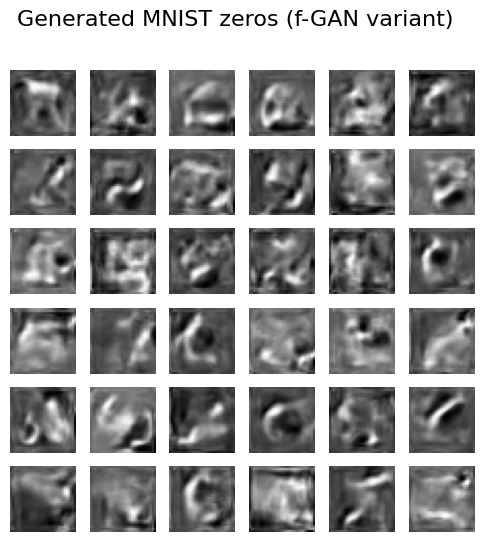

In [19]:
if RUN_FGAN:
    # Visualize final f-GAN generation results
    fG.eval()
    with torch.no_grad():
        final_fake_fgan = fG(36, device, noise_factor=1.0).cpu()

    plt.figure(figsize=(6, 6))
    for i in range(36):
        plt.subplot(6, 6, i+1)
        plt.imshow(process_image(final_fake_fgan[i]), cmap='gray')
        plt.axis("off")
    plt.suptitle("Generated MNIST zeros (f-GAN variant)", fontsize=16)
    plt.show()
else:
    print("f-GAN appendix skipped.")

### Optional reference only

Latent size and architecture widths are design choices, not image labels. Reducing inference noise variance changes the sampled latent distribution and may trade variety for appearance; it is not guaranteed to improve quality.

### Different extensions, different questions

Conditional GANs provide labels to both networks. f-GAN changes the divergence-based objective. WGAN introduces a transport-based critic objective; that belongs to seminar 4. None guarantees freedom from mode collapse.

### What this demonstration does not establish

GANs have useful evaluation metrics, but no single universal quality score. Training can be
unstable, diversity can collapse, and memorization is possible. We did not establish held-out
distribution matching or privacy. Short-run numerical correctness is not convergence.

Sources: [original GAN](https://arxiv.org/abs/1406.2661),
[f-GAN](https://arxiv.org/abs/1606.00709),
[PyTorch GAN tutorial](https://github.com/pytorch/tutorials/blob/main/beginner_source/dcgan_faces_tutorial.py),
[MNIST download](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).
